# Кластеризация ЕГЭ (8.5 если сделаны все задачи)

Рядом лежат экселевские таблицы с координатами точек. В 3 и 4 задаче используется манхетеское расстояние. В остальных Евклидово.

* Постройте Распределение точек
* Кластеризуйте руками
* Постройте Распределение точек, отметьте принадлежность кластеров цветами
* Найдите среди в каждом кластере точку расстояние от которой до всех остальных минимально
* Выведите усреднение центров всех кластеров * 1000

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np


# Кластеризация (0.75 за каждый алгоритм на всех данных)

На предложенных распределениях данных проверьте предложенные алгоритмы. Постройте графики кластеризации для каждой пары алгоритм-данные, разные кластеры покрасьте разным цветом. Воспользуйтесь sklearn реализациями. Параметры кластеризации для разных алгоритмов подберите такие, чтобы алгоритмы можно было сравнивать (по возможности одинаковое количество кластеров и т.д.)

In [2]:
import time
import warnings

import numpy as np
import matplotlib.pyplot as plt

from sklearn import cluster, datasets, mixture
from sklearn.neighbors import kneighbors_graph
from sklearn.preprocessing import StandardScaler
from itertools import cycle, islice

In [3]:
%pip install openpyxl xlrd

Note: you may need to restart the kernel to use updated packages.


In [4]:
from scipy.spatial.distance import cdist

files = {0: "0.xls", 1: "1.xls", 2: "2.xlsx", 3: "3.xlsx", 4: "4.xlsx", 5: "5.xlsx"}
metric = {k: ("cityblock" if k in (3, 4) else "euclidean") for k in files}

def load(path):
    df = pd.read_excel(path, header=None)
    df = df.apply(pd.to_numeric, errors="coerce").dropna()
    df.columns = ["X", "Y"]
    return df.reset_index(drop=True)

data = {k: load(f) for k, f in files.items()}
for k, d in data.items():
    print(k, d.shape)

0 (100, 2)
1 (9999, 2)
2 (1000, 2)
3 (10000, 2)
4 (500, 2)
5 (9999, 2)


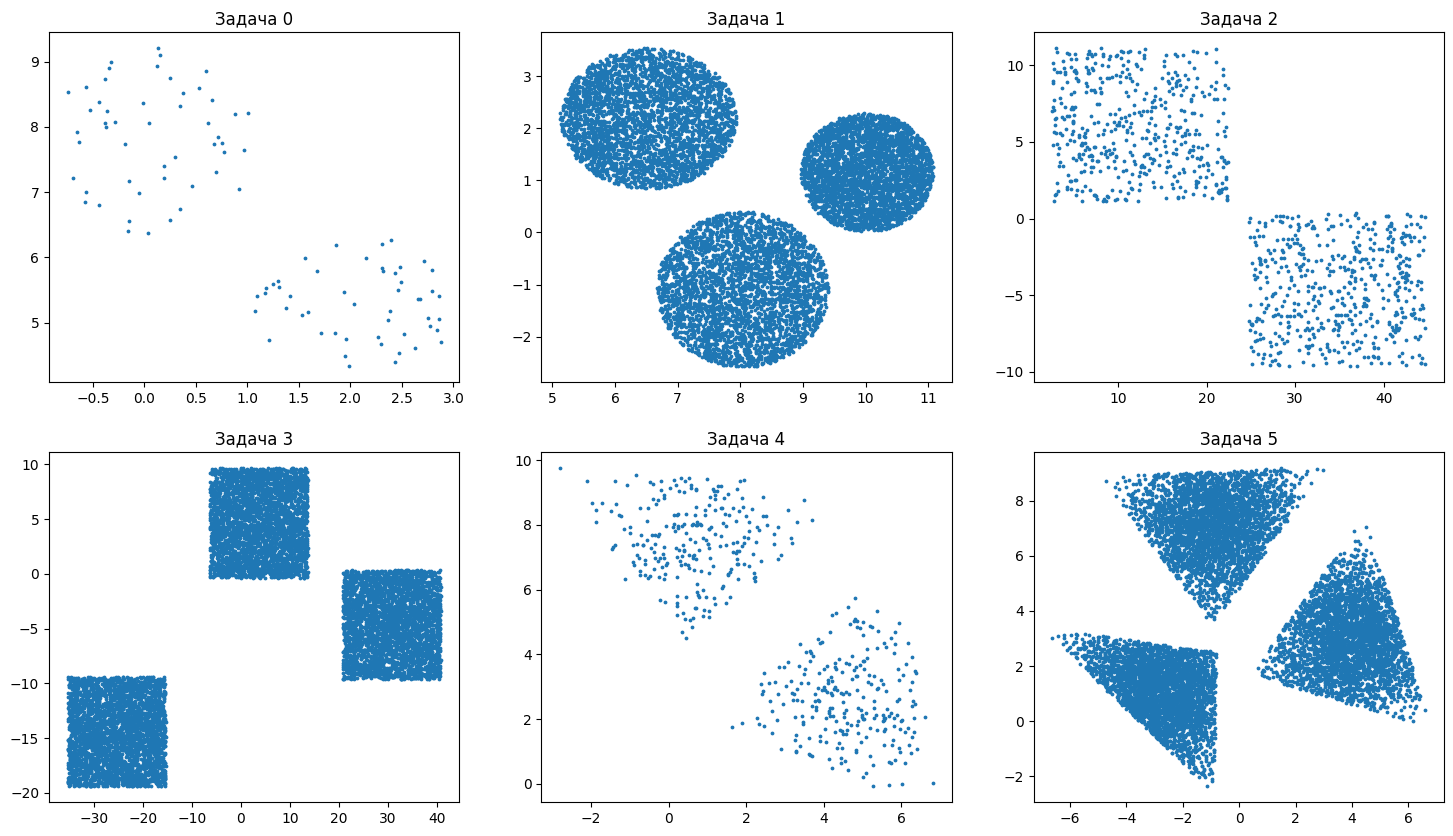

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
for k, ax in zip(data, axes.flat):
    ax.scatter(data[k].X, data[k].Y, s=3)
    ax.set_title(f"Задача {k}")
plt.show()

In [6]:
def rule0(d): return (d.Y > 6.3).astype(int)

def rule1(d):
    c = np.array([[6.5, 2.2], [10, 1.1], [8, -1]])
    return cdist(d.values, c).argmin(axis=1)

def rule2(d): return (d.Y > 0.7).astype(int)

def rule3(d): return np.where(d.X < -10, 0, np.where(d.X > 15, 2, 1))

def rule4(d): return ((d.Y - 0.5 * d.X) > 3.8).astype(int)

def rule5(d):
    c = np.array([[-1, 7], [-3, 0.5], [4, 3]])
    return cdist(d.values, c).argmin(axis=1)

rules = {0: rule0, 1: rule1, 2: rule2, 3: rule3, 4: rule4, 5: rule5}
labels = {k: np.asarray(rules[k](data[k])) for k in data}
for k, l in labels.items():
    print(k, "размеры кластеров:", np.bincount(l))

0 размеры кластеров: [50 50]
1 размеры кластеров: [3333 3333 3333]
2 размеры кластеров: [524 476]
3 размеры кластеров: [3429 3284 3287]
4 размеры кластеров: [250 250]
5 размеры кластеров: [3333 3333 3333]


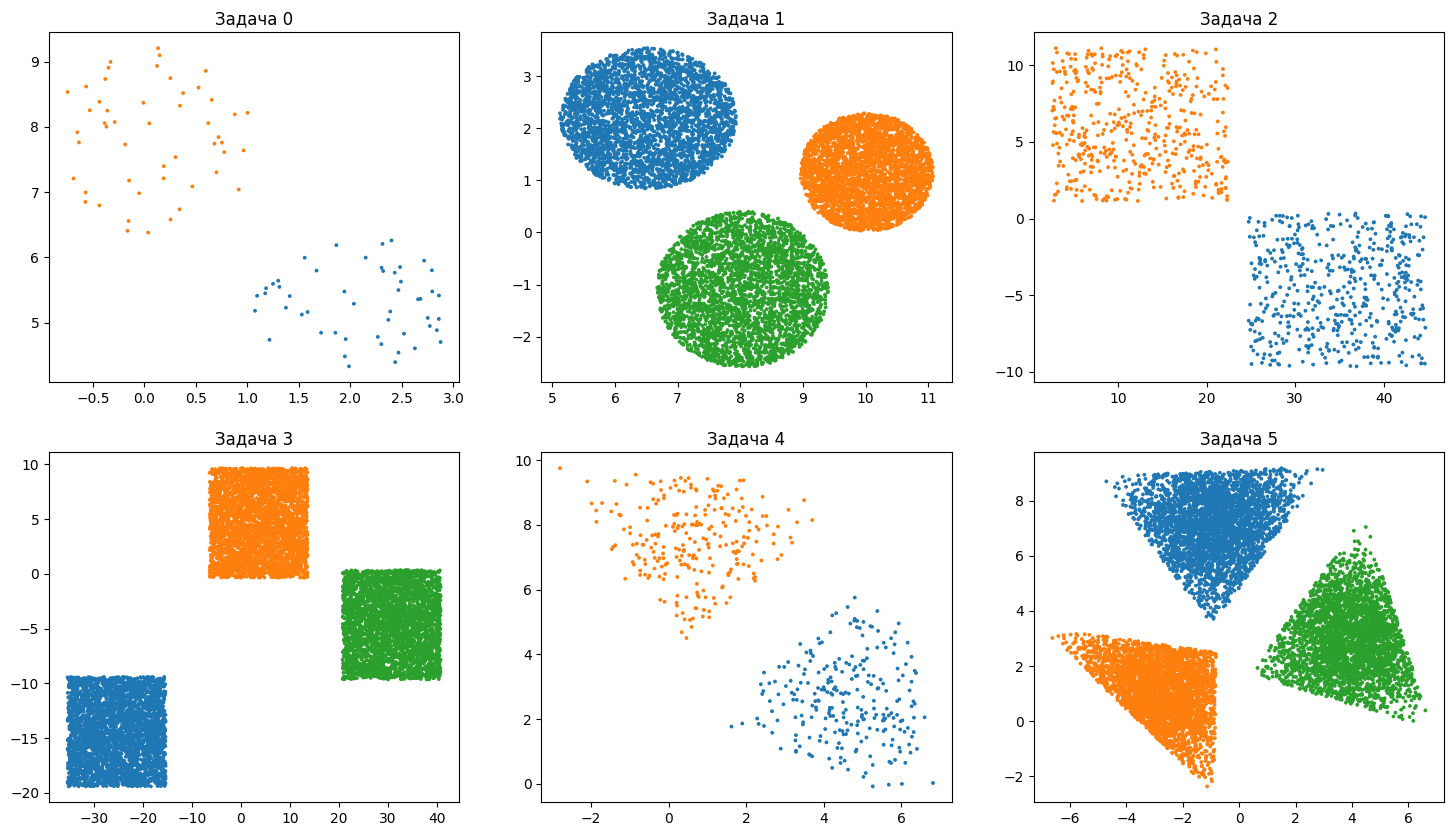

In [7]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
for k, ax in zip(data, axes.flat):
    ax.scatter(data[k].X, data[k].Y, c=labels[k], s=3, cmap="tab10", vmin=0, vmax=9)
    ax.set_title(f"Задача {k}")
plt.show()

In [8]:
def medoid(points, dist):
    D = cdist(points, points, metric=dist)
    return points[D.sum(axis=1).argmin()]

centers = {}
for k in data:
    pts = data[k].values
    centers[k] = np.array([medoid(pts[labels[k] == c], metric[k]) for c in np.unique(labels[k])])
    print(f"Задача {k} ({metric[k]}):")
    print(np.round(centers[k], 4))

Задача 0 (euclidean):
[[2.0339 5.2893]
 [0.0481 8.0531]]
Задача 1 (euclidean):
[[ 6.47    2.1698]
 [10.0225  1.1542]
 [ 8.0401 -1.1087]]
Задача 2 (euclidean):
[[34.9264 -4.6953]
 [11.3341  5.966 ]]
Задача 3 (cityblock):
[[-25.1308 -14.4133]
 [  3.5179   4.6537]
 [ 30.8495  -4.5172]]
Задача 4 (cityblock):
[[4.4993 2.5248]
 [0.6778 7.4683]]
Задача 5 (euclidean):
[[-0.924   7.1199]
 [-2.7497  1.1431]
 [ 3.8586  2.9072]]


In [9]:
for k in data:
    m = centers[k].mean(axis=0) * 1000
    print(f"Задача {k}: Px = {int(m[0])}, Py = {int(m[1])}   (точные: {m[0]:.3f}, {m[1]:.3f})")

Задача 0: Px = 1041, Py = 6671   (точные: 1041.006, 6671.173)
Задача 1: Px = 8177, Py = 738   (точные: 8177.531, 738.419)
Задача 2: Px = 23130, Py = 635   (точные: 23130.216, 635.342)
Задача 3: Px = 3078, Py = -4758   (точные: 3078.894, -4758.945)
Задача 4: Px = 2588, Py = 4996   (точные: 2588.540, 4996.568)
Задача 5: Px = 61, Py = 3723   (точные: 61.652, 3723.362)


In [10]:
from sklearn.base import clone

two_means = cluster.MiniBatchKMeans(n_clusters=3, n_init=3, random_state=0)
dbscan = cluster.DBSCAN(eps=0.3, min_samples=20)

# Дополнительные алгоритмы
ward = cluster.AgglomerativeClustering(n_clusters=3, linkage="ward")
birch = cluster.Birch(n_clusters=3)
gmm = mixture.GaussianMixture(n_components=3, covariance_type="full", random_state=0)
spectral = cluster.SpectralClustering(n_clusters=3, eigen_solver="arpack",
                                      affinity="nearest_neighbors", random_state=0)

clustering_algorithms = (
        ("MiniBatch\nKMeans", two_means),
        ("DBSCAN", dbscan),
        ("Ward", ward),
        ("Birch", birch),
        ("Gaussian\nMixture", gmm),
        ("Spectral\nClustering", spectral),
    )

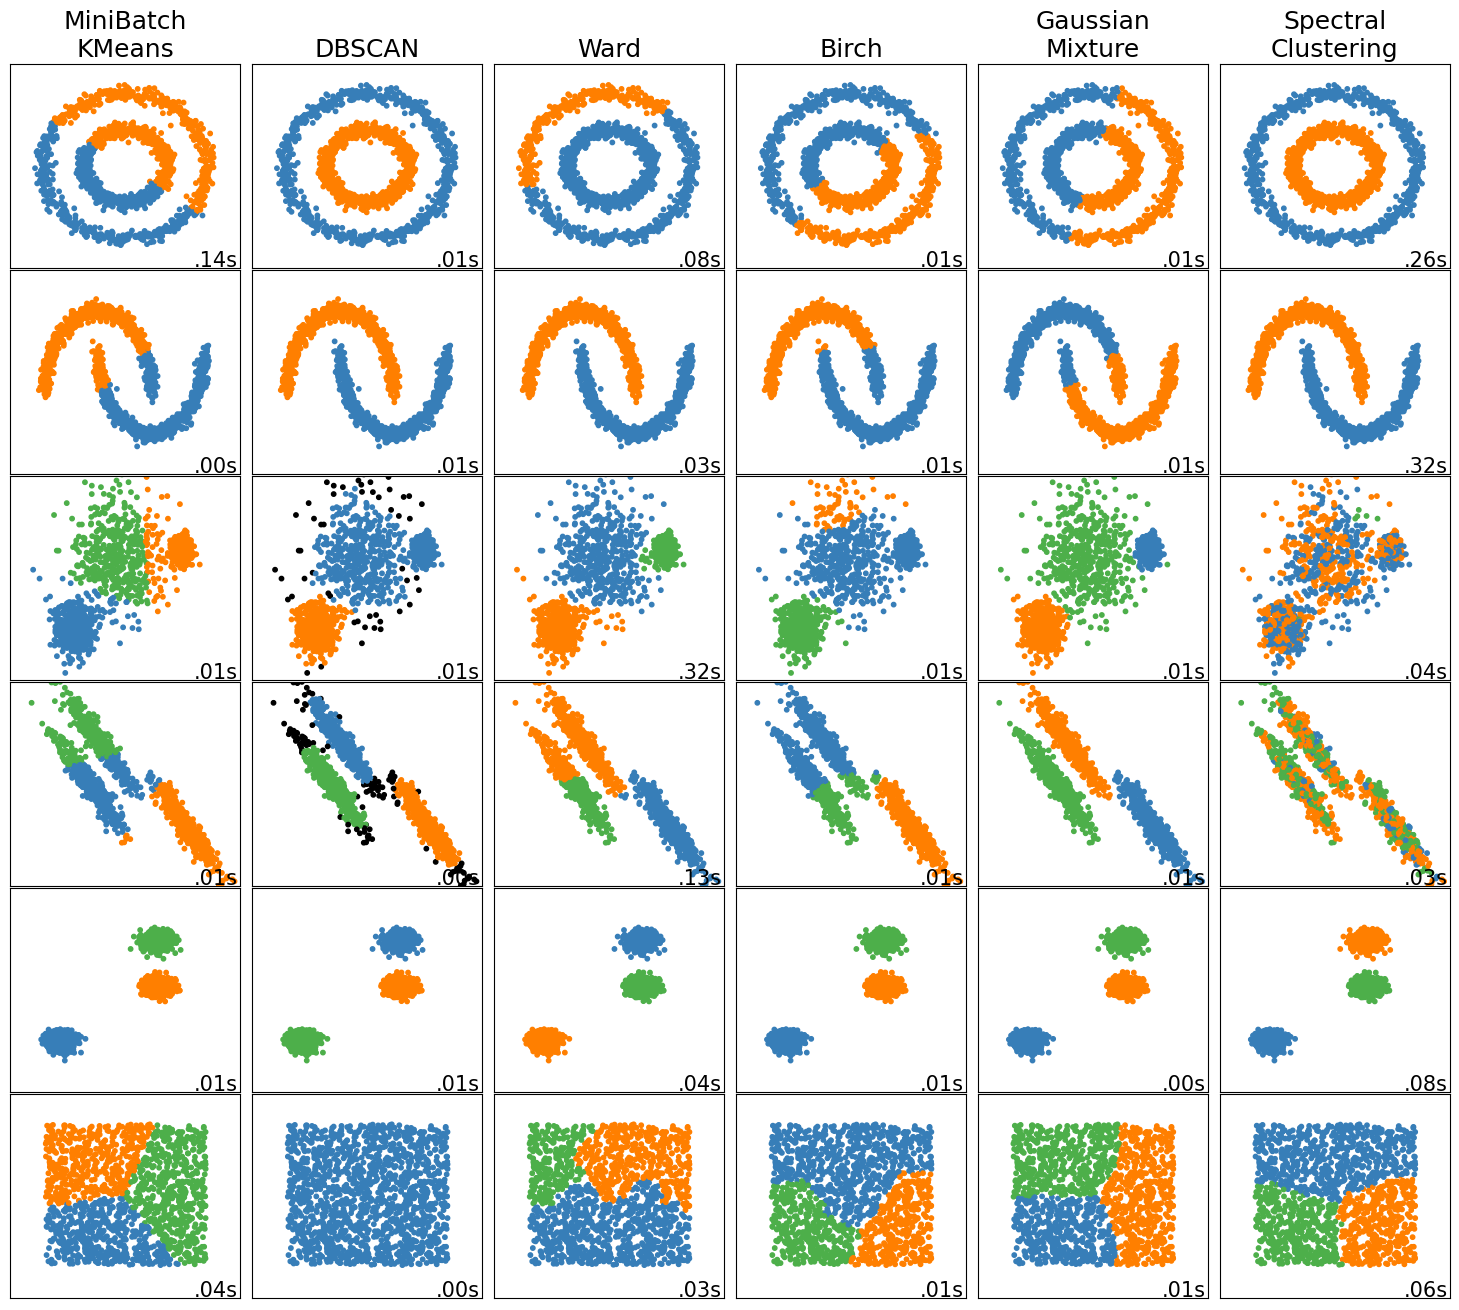

In [11]:
np.random.seed(0)

# ============
# Generate datasets. We choose the size big enough to see the scalability
# of the algorithms, but not too big to avoid too long running times
# ============
n_samples = 1500
noisy_circles = datasets.make_circles(n_samples=n_samples, factor=0.5, noise=0.05)
noisy_moons = datasets.make_moons(n_samples=n_samples, noise=0.05)
blobs = datasets.make_blobs(n_samples=n_samples, random_state=8)
no_structure = np.random.rand(n_samples, 2), None

# Anisotropicly distributed data
random_state = 170
X, y = datasets.make_blobs(n_samples=n_samples, random_state=random_state)
transformation = [[0.6, -0.6], [-0.4, 0.8]]
X_aniso = np.dot(X, transformation)
aniso = (X_aniso, y)

# blobs with varied variances
varied = datasets.make_blobs(
    n_samples=n_samples, cluster_std=[1.0, 2.5, 0.5], random_state=random_state
)

# ============
# Set up cluster parameters
# ============
plt.figure(figsize=(len(clustering_algorithms) * 2 + 3, 13))
plt.subplots_adjust(
    left=0.02, right=0.98, bottom=0.001, top=0.95, wspace=0.05, hspace=0.01
)

plot_num = 1

default_base = {
    "quantile": 0.3,
    "eps": 0.3,
    "damping": 0.9,
    "preference": -200,
    "n_neighbors": 10,
    "n_clusters": 3,
    "min_samples": 20,
    "xi": 0.05,
    "min_cluster_size": 0.1,
}

cluster_datasets = [
    (
        noisy_circles,
        {
            "damping": 0.77,
            "preference": -240,
            "quantile": 0.2,
            "n_clusters": 2,
            "min_samples": 20,
            "xi": 0.25,
        },
    ),
    (noisy_moons, {"damping": 0.75, "preference": -220, "n_clusters": 2}),
    (
        varied,
        {
            "eps": 0.18,
            "n_neighbors": 2,
            "min_samples": 5,
            "xi": 0.035,
            "min_cluster_size": 0.2,
        },
    ),
    (
        aniso,
        {
            "eps": 0.15,
            "n_neighbors": 2,
            "min_samples": 20,
            "xi": 0.1,
            "min_cluster_size": 0.2,
        },
    ),
    (blobs, {}),
    (no_structure, {}),
]

for i_dataset, (dataset, algo_params) in enumerate(cluster_datasets):
    # update parameters with dataset-specific values
    params = default_base.copy()
    params.update(algo_params)

    X, y = dataset

    # normalize dataset for easier parameter selection
    X = StandardScaler().fit_transform(X)

    # estimate bandwidth for mean shift
    bandwidth = cluster.estimate_bandwidth(X, quantile=params["quantile"])

    # connectivity matrix for structured Ward
    connectivity = kneighbors_graph(
        X, n_neighbors=params["n_neighbors"], include_self=False
    )
    # make connectivity symmetric
    connectivity = 0.5 * (connectivity + connectivity.T)

    for name, algorithm in clustering_algorithms:
        t0 = time.time()

        # подставляем параметры текущего набора данных в алгоритм (если алгоритм их поддерживает)
        algorithm = clone(algorithm)
        overrides = {
            "n_clusters": params["n_clusters"],
            "n_components": params["n_clusters"],
            "eps": params["eps"],
            "min_samples": params["min_samples"],
            "n_neighbors": params["n_neighbors"],
            "connectivity": connectivity,
        }
        valid = algorithm.get_params().keys()
        algorithm.set_params(**{p: v for p, v in overrides.items() if p in valid})

        with warnings.catch_warnings():
            warnings.filterwarnings(
                "ignore",
                message="the number of connected components of the "
                + "connectivity matrix is [0-9]{1,2}"
                + " > 1. Completing it to avoid stopping the tree early.",
                category=UserWarning,
            )
            warnings.filterwarnings(
                "ignore",
                message="Graph is not fully connected, spectral embedding"
                + " may not work as expected.",
                category=UserWarning,
            )
            algorithm.fit(X)
        t1 = time.time()

        if hasattr(algorithm, "labels_"):
            y_pred = algorithm.labels_.astype(int)
        else:
            y_pred = algorithm.predict(X)

        plt.subplot(len(cluster_datasets), len(clustering_algorithms), plot_num)
        if i_dataset == 0:
            plt.title(name, size=18)

        colors = np.array(
            list(
                islice(
                    cycle(
                        ["#377eb8", "#ff7f00", "#4daf4a", "#f781bf", "#a65628",
                         "#984ea3", "#999999", "#e41a1c", "#dede00"]
                    ),
                    int(max(y_pred) + 1),
                )
            )
        )
        # чёрный цвет для шума (метка -1 у DBSCAN)
        colors = np.append(colors, ["#000000"])
        plt.scatter(X[:, 0], X[:, 1], s=10, color=colors[y_pred])

        plt.xlim(-2.5, 2.5)
        plt.ylim(-2.5, 2.5)
        plt.xticks(())
        plt.yticks(())
        plt.text(0.99, 0.01, ("%.2fs" % (t1 - t0)).lstrip("0"),
                 transform=plt.gca().transAxes, size=15, horizontalalignment="right")
        plot_num += 1

plt.show()
